# 01 – GFlash-like formula for the pion shower

## 1. Introduction

In the detector metal a pion (mass 0.14 GeV) starts a **hadronic shower**: through strong interactions with nuclei it creates new hadrons
(mainly pions), which collide further, and so on. The produced $\pi^0$s immediately decay into two photons, which
start **electromagnetic sub-showers** inside the hadronic shower. Compared with the electron shower, the hadronic shower is
- **longer**: the scale is the nuclear interaction length ($\lambda_{int}$, approx. 170 mm in iron), not the radiation length ($X_0 \approx 18$ mm);
- **wider**: the lateral tail extends over several cells;
- **much more fluctuating**: the depth of the first interaction is exponentially distributed, and the electromagnetic fraction varies event by event.

It is like a **branching tree**: the first branching point is random, and from there several overlapping branches start.

The GFlash parametrisation uses the same product form for hadrons:

$$\rho(r, z' \mid p) = \underbrace{L(z' \mid p)}_{\text{depth profile}} \cdot \underbrace{T(r \mid z', p)}_{\text{cross-section}}$$

- **Depth, $L$:** Gamma distribution, $L \propto s^{\alpha-1} e^{-(\alpha-1)s/t_{max}}$, where $s = z' - z_0$. For hadrons the position of the maximum is
  approx. $t_{max} \approx \lambda_{int}\,(0.2 \ln E + 0.7)$, also growing logarithmically with energy. The original hadronic GFlash sums several
  Gamma terms (EM and hadronic parts, start-point fluctuation); here we fit the **single-term** version, with the same code
  as for the electron, so that the formulas remain comparable.
- **Cross-section, $T$:** narrow core (the EM sub-showers) and wide tail (the hadronic part), with two Cauchy terms.

**Coordinates (shower-local coordinates):**
- $z'$ (`z_local`): depth along the direction of incidence, in mm. The origin is the centroid of the first hit layer, so for oblique incidence negative $z'$ also occurs.
- $r = \sqrt{x_{local}^2 + y_{local}^2}$: the hit's **perpendicular distance from the shower axis** (the line of the incoming particle), in mm.
  The shape is assumed cylindrically symmetric, so the azimuthal angle does not appear. 2D plots show $r$ mirrored ($\pm r$).
- The measured $r$ is that of the **cell centre** (cell ~48 mm). For hadrons the shower width is comparable to the cell size, so the lateral profile
  is better constrained by the data here than for the electron.
- **End of the grid:** the common $(z', r)$ grid extends to $Z_{MAX} = 1450$ mm; the hadronic shower tail may extend beyond it and is removed by the cuts.

Every parameter is linear in $\ln p$; the lateral parameters may also vary with depth. About 15 parameters in total.
This formula is fitted **directly to the data**; it is the physical reference (baseline) for the pion.

**Reference:**
- G. Grindhammer, M. Rudowicz, S. Peters: *The fast simulation of electromagnetic and hadronic showers*,
  Nucl. Instrum. Meth. A 290 (1990) 469, [doi:10.1016/0168-9002(90)90566-O](https://doi.org/10.1016/0168-9002(90)90566-O). This is the source of the hadronic parametrisation.
- G. Grindhammer, S. Peters: *The Parameterized Simulation of Electromagnetic Showers in Homogeneous and Sampling Calorimeters*,
  [arXiv:hep-ex/0001020](https://arxiv.org/abs/hep-ex/0001020) (the EM part, see 01_gflash_electron).


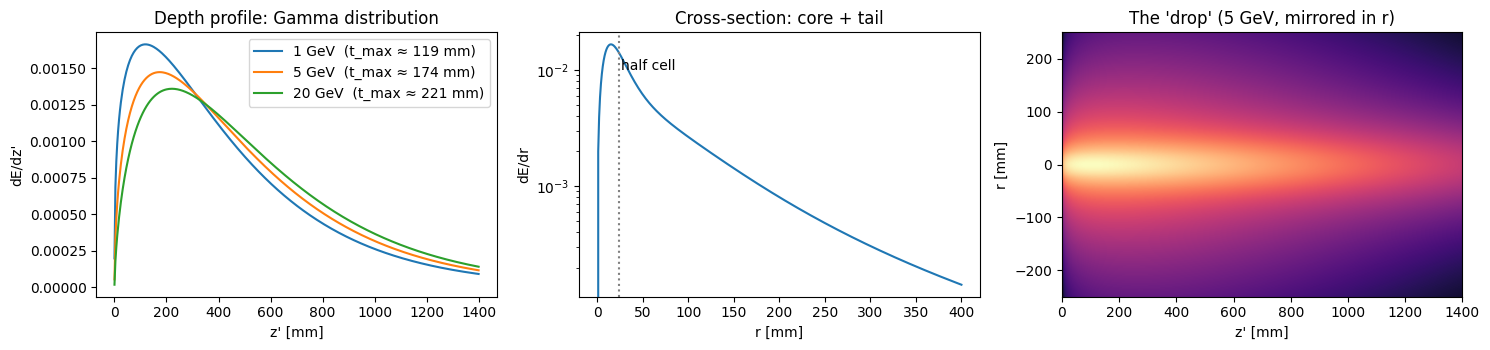

In [1]:
import numpy as np, matplotlib.pyplot as plt

LAM = 170.0                                 # illustrative: nuclear interaction length [mm]
z = np.linspace(0.1, 1400, 400)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for E in (1, 5, 20):
    tmax = LAM * (0.2 * np.log(E) + 0.7); b = 0.5 / LAM; a = 1 + b * tmax
    L = z ** (a - 1) * np.exp(-b * z)
    ax[0].plot(z, L / np.trapezoid(L, z), label=f"{E} GeV  (t_max ≈ {tmax:.0f} mm)")
ax[0].set(title="Depth profile: Gamma distribution", xlabel="z' [mm]", ylabel="dE/dz'"); ax[0].legend()
r = np.linspace(0, 400, 400); Rc, Rt, pc = 25.0, 110.0, 0.6
T = (pc * Rc**2 / (r**2 + Rc**2)**2 + (1 - pc) * Rt**2 / (r**2 + Rt**2)**2) / np.pi
ax[1].semilogy(r, 2 * np.pi * r * T); ax[1].axvline(24, ls=":", c="grey"); ax[1].text(26, 1e-2, "half cell")
ax[1].set(title="Cross-section: core + tail", xlabel="r [mm]", ylabel="dE/dr")
Z, R = np.meshgrid(z, np.linspace(-250, 250, 241))
tmax = LAM * (0.2 * np.log(5) + 0.7); b = 0.5 / LAM; a = 1 + b * tmax
rc = Rc * (1 + Z / 800)
rho = Z ** (a - 1) * np.exp(-b * Z) * (pc * rc**2 / (R**2 + rc**2)**2 + (1 - pc) * (4 * rc)**2 / (R**2 + (4 * rc)**2)**2)
ax[2].imshow(np.log10(rho + 1e-30), extent=[0, 1400, -250, 250], aspect="auto", origin="lower", cmap="magma",
             vmin=np.log10(rho.max()) - 4)
ax[2].set(title="The 'drop' (5 GeV, mirrored in r)", xlabel="z' [mm]", ylabel="r [mm]")
plt.tight_layout(); plt.show()

## 2. Loading data

In [2]:
PARTICLES = ['pion']
DATA_DIR = "../../data/simulations/regression-pion/"          # location of the CSVs
OUT_DIR = "results"        # models and exports go here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-pion/ | output: results


In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

pion: 99689 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69783, val 14950, test 14956

===== pion =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49110973 entries, 0 to 49110972
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                floa

,count,mean,std,min,25%,50%,75%,max
event_number,49110973.0,1.050066e+05,6.065561e+04,0.000000e+00,5.237000e+04,1.050170e+05,1.575570e+05,2.099970e+05
cellID,49110973.0,2.090493e+09,1.473656e+09,4.212000e+03,7.221679e+08,1.753932e+09,3.309956e+09,5.063386e+09
x,49110973.0,3.218513e+00,1.306847e+03,-2.596035e+03,-1.036428e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,49110973.0,-2.283059e+00,1.307162e+03,-2.599800e+03,-1.036200e+03,2.620000e+01,1.036200e+03,2.599800e+03
z,49110973.0,4.091779e+03,2.837958e+02,3.662400e+03,3.867400e+03,4.051900e+03,4.277400e+03,4.871900e+03
x_local,49110973.0,-3.666150e+01,2.144154e+02,-4.968845e+03,-1.326416e+02,-2.568672e+01,6.705917e+01,4.137740e+03
y_local,49110973.0,2.505265e-01,2.130792e+02,-3.721291e+03,-1.014420e+02,0.000000e+00,1.017206e+02,3.125906e+03
z_local,49110973.0,4.471790e+02,3.021535e+02,-2.985229e+03,2.110727e+02,3.987507e+02,6.431534e+02,2.933382e+03
x_trans,49110973.0,7.058134e-01,2.452876e+02,-4.806044e+03,-1.353739e+02,0.000000e+00,1.376407e+02,5.016641e+03
y_trans,49110973.0,-2.141510e-01,2.452217e+02,-5.128854e+03,-1.368652e+02,0.000000e+00,1.354339e+02,4.766881e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,32577,2844239732,-1233.912964,-377.799988,4379.899902,174.624418,-6.043664,785.270612,-350.431969,-97.833189,...,1.627338e-05,37.407822,18.368912,0.250428,-2.852734,18,proton,1,neutron,NaN
1,117646,3947026804,128.524002,1440.199951,4625.899902,-1151.930652,178.009222,427.047158,-373.923903,-687.640495,...,1.829786e-05,35.721050,1.610262,0.546492,1.302170,1,neutron,1,neutron,NaN
2,113305,2281791604,-430.761993,2094.800049,4359.399902,172.598498,-397.387051,833.346339,177.570017,604.013841,...,7.539088e-05,11227.231445,18.748279,0.406894,1.967967,18,gamma,1,neutron,NaN
3,141634,4387483508,-2041.468018,1137.199951,4031.399902,-93.626889,3.687866,374.588895,-100.943970,52.399902,...,1.757939e-07,195.216415,10.812306,0.543763,2.630352,10,neutron,1,neutron,gamma;gamma;gamma
4,132530,3913543284,-1892.254028,1036.199951,4420.899902,-338.212858,507.919669,679.356918,-359.455044,-359.674814,...,1.385399e-08,3079.680420,16.386311,0.493974,2.404347,16,neutron,1,neutron,NaN


## 3. The model

The formula is the common notebook's `Formula` class: longitudinal part `gamma`, lateral part `core_tail`; the parameters are
**first-degree** polynomials in $\ln p$, and the lateral parameters also have a depth slope.
Initial values are estimated from the data: mean depth, depth spread, median radius.

### What is fitted, and what affects the fit?

**Fitted features (in the likelihood):**
- **Position:** `x_local, y_local, z_local` → $z' =$ `z_local`, $r = \sqrt{x_{local}^2 + y_{local}^2}$. The formula sees only these two coordinates.
- **Weight:** `energy`, normalised to 1 per event ($w_i$). The fit seeks the energy-weighted **mean shape**; every event counts equally.
- **Condition:** `incoming_momentum` → $\ln p$. Every formula parameter is a polynomial in $\ln p$, so a single fit gives the shape for all momenta.
- **Grouping:** `event_number`: normalisation and NLL are computed per event.

**What affects the fit but is not a fitted target:**
- `incoming_theta`, `incoming_phi` → rotation: used to rotate the detector cell into the shower frame for the convolution.
- `z`, `z_trans` (+ `incoming_theta`) → the detector back face along the axis ($z_b$). The likelihood normalisation only considers the part in front of the back face; the shape beyond it is not constrained by data.
- `x`, `y`, `z` → geometry: cell size (~48 mm) and layer spacing (~20.5 mm). This is how much the formula is "smeared" before comparison with the data.
- **Cuts:** `earliest_contribution_time` < 100 ns, $Z_{MIN} \le z' \le Z_{MAX}$, $r < R_{MAX}$.
- `incoming_momentum_bin` → only needed for stratifying the train/val/test split.
- **Initial values** (`init_from`): from the training hits' $z'$, $r$, $w$ (weighted mean depth, depth spread, median radius).
- **Training:** Adam optimiser (`lr`), early stopping on the validation NLL (`patience=15`). No smoothness penalty, since the formula is smooth by construction.

In [4]:
data = DATA["pion"]
h = data["train"].hits()
model = Formula("gamma", "core_tail", degree=1).init_from(h.z.values, h.r.values, h.w.values).to(DEVICE)
print("parameters:", model.n_params())
display(Markdown(model.describe("Initial values")))

parameters: 15


/tmp/ipykernel_322044/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### Initial values

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-20 +0\,L$ | – |
| `log_tmax` | $+4.807 +0\,L$ | – |
| `log_am1` | $-0.5951 +0\,L$ | – |
| `log_rc` | $+3.367 +0\,L$ | +0 |
| `log_ratio` | $+1.099 +0\,L$ | +0 |
| `logit_pc` | $+0.85 +0\,L$ | +0 |

Number of parameters: **15**

## 4. Training

Training minimises the common likelihood: the formula, convolved with the detector cell, is compared with the measured hits.
The model is saved to `results/pion/gflash.pt`; if training has already run, it is just loaded.

Settings: `epochs=150`, `lr=0.03`, pion data only. The hadronic shower width is comparable to the cell size (~48 mm), so the lateral parameters (`rc`, `ratio`, `pc`) are constrained more directly by the data here than for the electron. Because of the long tail, part of the depth profile may lie beyond the end of the grid ($Z_{MAX}$).

loaded finished model from results/pion/gflash.pt


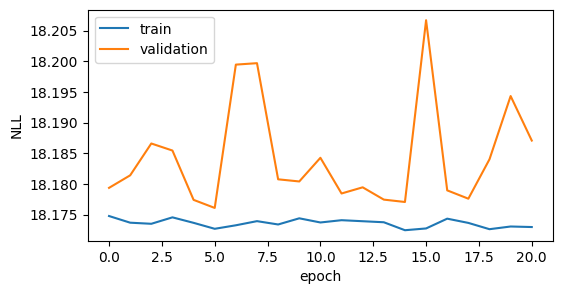

In [5]:
hist = fit(model, data, f"{OUT_DIR}/pion/gflash.pt", epochs=150, lr=0.03)
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 4b. Selecting the degree of the $\ln p$ polynomial

Besides the $n=1$ model above, we also fit degrees $n = 1 \dots 6$ (`select_degree`; protocol in section 7 of the common notebook).
The degree is chosen on the **validation** set; the **test** set only measures the final model. Models are saved to `results/pion/gflash_n<n>.pt`;
a completed training is just loaded.

**What to look for:** the train curve always decreases with $n$. If the validation curve flattens or turns back, further
degrees only fit noise.

--- degree 1 ---
loaded finished model from results/pion/gflash_n1.pt


--- degree 2 ---
loaded finished model from results/pion/gflash_n2.pt


--- degree 3 ---
loaded finished model from results/pion/gflash_n3.pt


--- degree 4 ---
loaded finished model from results/pion/gflash_n4.pt


--- degree 5 ---
loaded finished model from results/pion/gflash_n5.pt


--- degree 6 ---
loaded finished model from results/pion/gflash_n6.pt


lowest validation NLL: n* = 3;  chosen by the 1-SE rule: n = 3


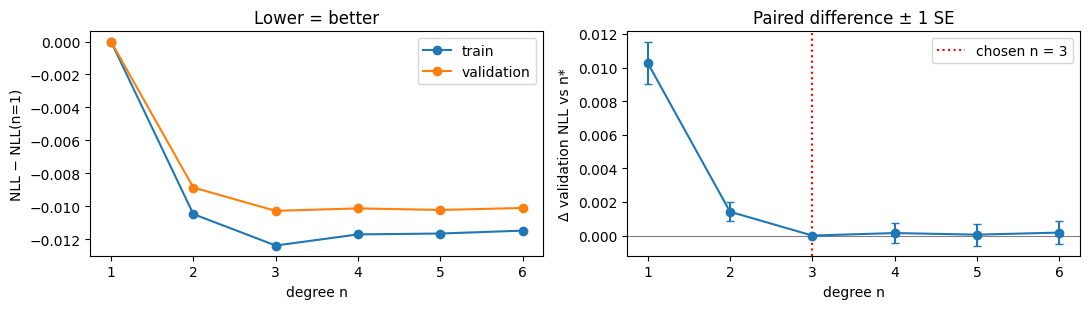

,params,train NLL,val NLL,epochs,Δval vs n*,SE,chosen
n,,,,,,,
1,15,18.1599,18.1690,27,0.0103,0.0013,
2,21,18.1494,18.1602,20,0.0014,0.0006,
3,27,18.1475,18.1587,21,0.0000,0.0000,◀
4,33,18.1482,18.1589,20,0.0001,0.0006,
5,39,18.1483,18.1588,20,0.0001,0.0006,
6,45,18.1484,18.1589,20,0.0002,0.0007,


chosen degree: 3 | test NLL n=1: 18.1709 | chosen: 18.1563


In [6]:
model_n1 = model
model, DEGREE_TABLE, DEGREE_MODELS = select_degree("gamma", "core_tail", data, "pion", "gflash", degrees=range(1, 7),
                                                   epochs=150, lr=0.03)
display(DEGREE_TABLE.round(4))
print("chosen degree:", model.degree, "| test NLL n=1:", round(float(test_nll(model_n1, data["test"]).mean()), 4),
      "| chosen:", round(float(test_nll(model, data["test"]).mean()), 4))

## 6. Results

**What to look for:**
- **Profiles:** how well the black (data) and blue (model) curves overlap at different momenta. For the pion the depth profile
  matters more; the lateral profile is largely set by the cell size.
- **Parameters:** `tmax` (position of the maximum) should grow with momentum; the tail weight ($1-p_c$) is much larger for hadrons than for electrons.
- **3D:** the body should be "drop"-shaped, longer and thicker with increasing momentum.

### The fitted GFlash formula

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=(\ln(p/\mathrm{GeV}) -0.2912)/2.705$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-20.71 -3.613\,L +9.392\,L^2 +0.9912\,L^3$ | – |
| `log_tmax` | $+4.192 +1.182\,L -0.903\,L^2 +0.4643\,L^3$ | – |
| `log_am1` | $-0.8632 -0.2769\,L +0.7155\,L^2 -0.3645\,L^3$ | – |
| `log_rc` | $+3.181 +0.226\,L -0.7617\,L^2 +0.5568\,L^3$ | +0.9312 |
| `log_ratio` | $+0.9186 -0.7144\,L +0.2603\,L^2 +0.3279\,L^3$ | +0.7853 |
| `logit_pc` | $+0.2552 -2.195\,L +2.917\,L^2 -0.9196\,L^3$ | +0.3919 |

Number of parameters: **27**

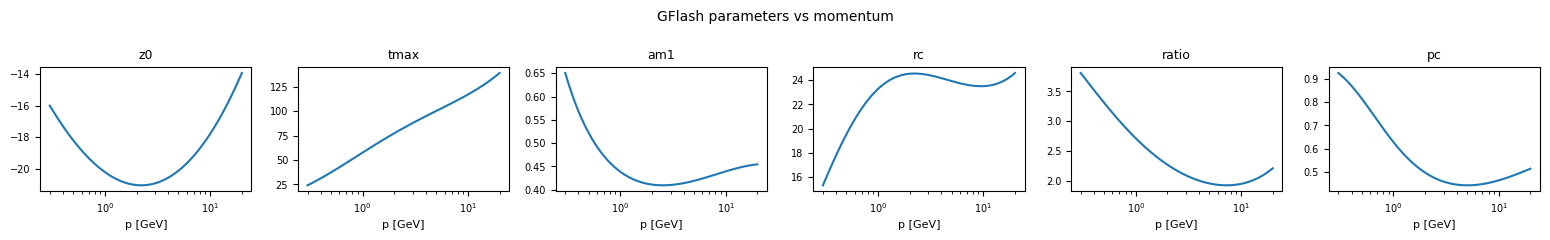

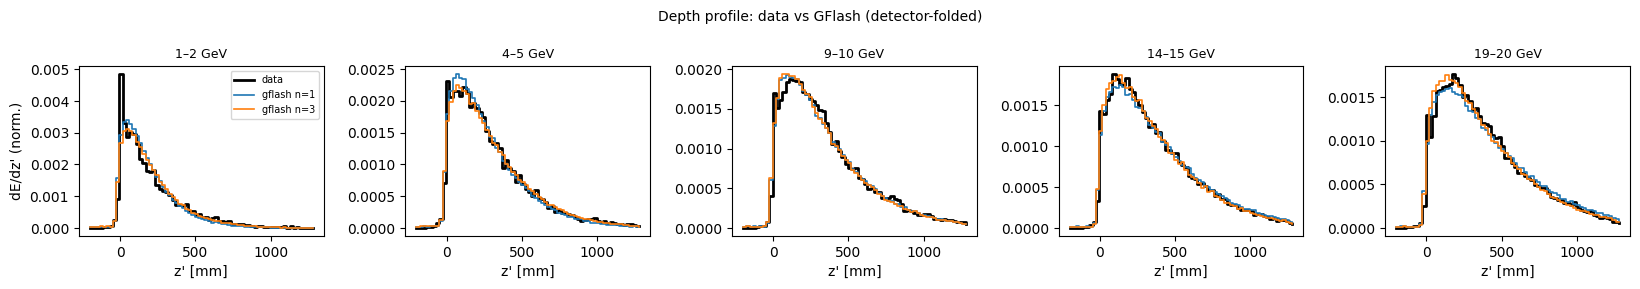

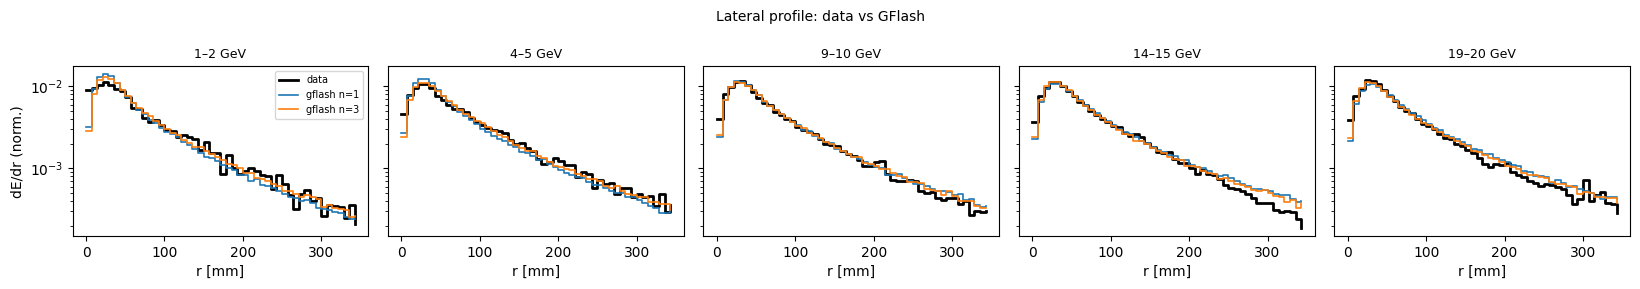

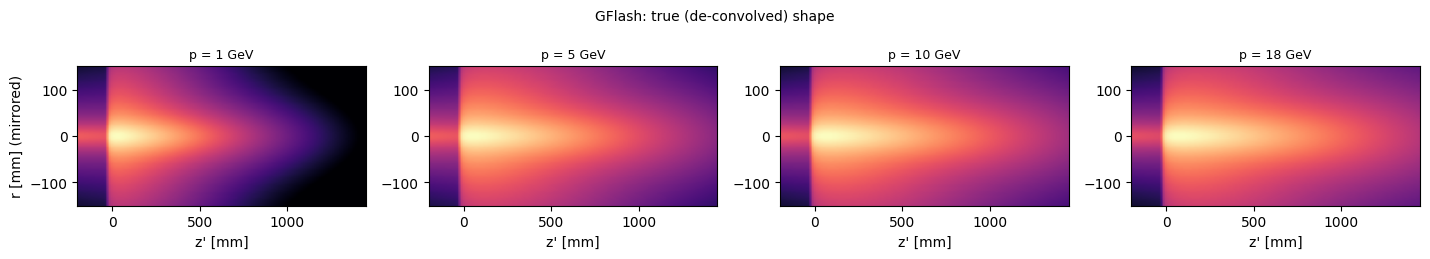

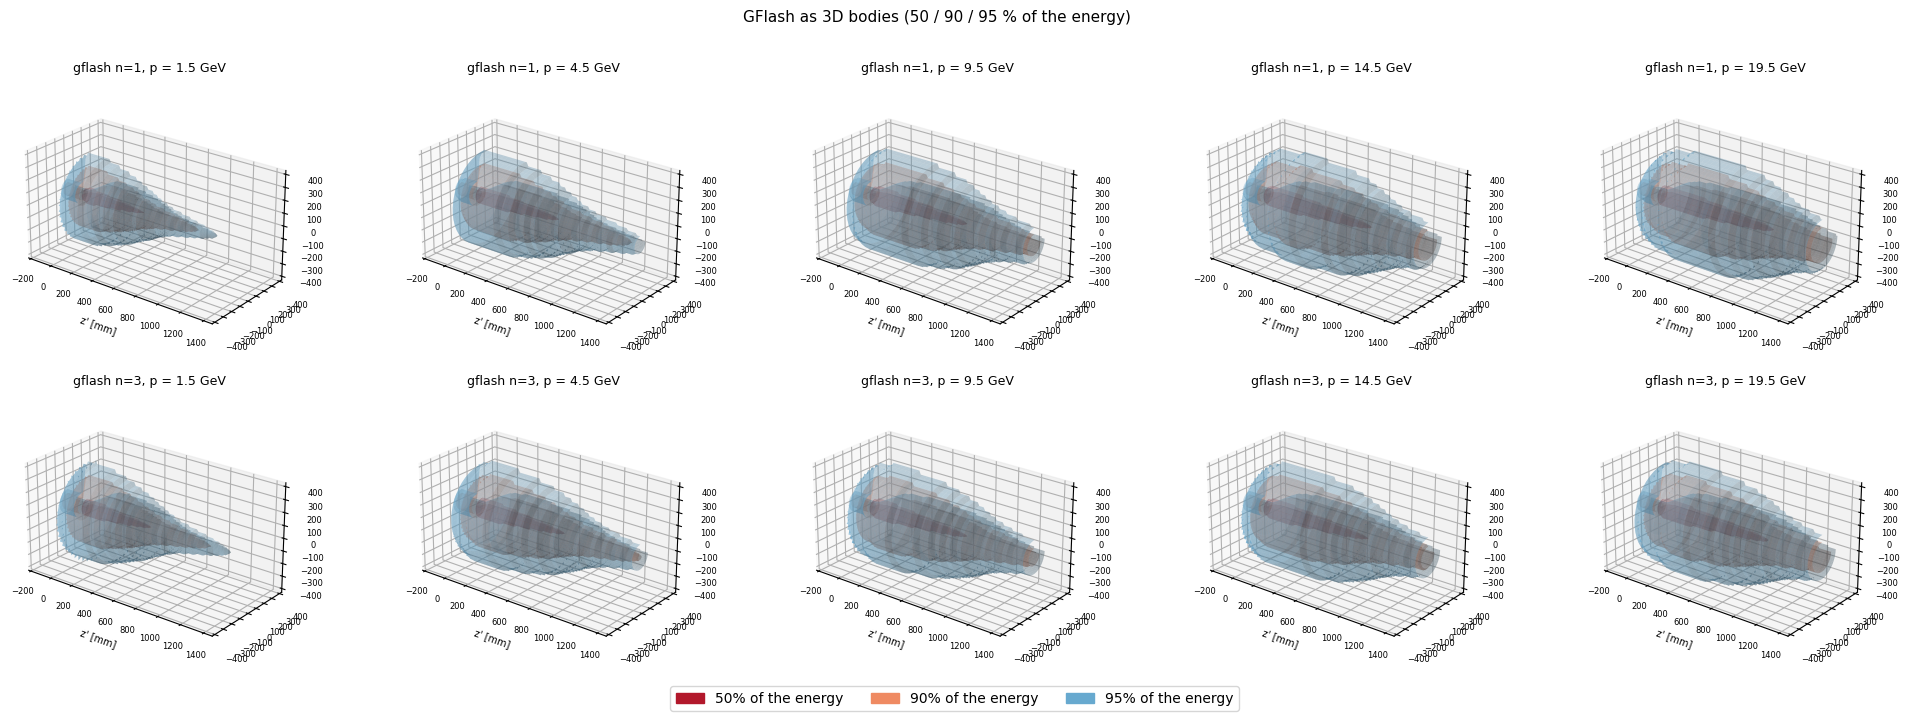

exported pion/gflash: test NLL = 18.1563


In [7]:
display(Markdown(model.describe("The fitted GFlash formula")))
formula_curves(model, "GFlash parameters vs momentum")
samples = {"gflash n=1": sample_folded(model_n1, data["test"]), f"gflash n={model.degree}": sample_folded(model, data["test"])}
hits = data["test"].hits()
profile_plot(hits, samples, "z", "Depth profile: data vs GFlash (detector-folded)")
profile_plot(hits, samples, "r", "Lateral profile: data vs GFlash")
shape_map(model, title="GFlash: true (de-convolved) shape")
bodies_3d({"gflash n=1": model_n1, f"gflash n={model.degree}": model}, title="GFlash as 3D bodies (50 / 90 / 95 % of the energy)")
export("pion", "gflash", model, data, model.describe("GFlash (pion baseline)"))